# Лабораторная работа №4 — Аугментация данных и трансферное обучение
## Дисциплина: Нейронные сети и глубокое обучение
**Датасет:** Собственный датасет (фрукты / овощи / ягоды)  
**Фреймворк:** Keras 3 (PyTorch backend) + ImageDataGenerator

---
## 0. Импорты и настройка

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import json, gc
from datetime import datetime

import torch
import kagglehub
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout, GlobalAveragePooling2D, Flatten
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
import kagglehub
dataset_path = kagglehub.dataset_download('puneet6060/intel-image-classification')
TRAIN_PATH = os.path.join(dataset_path, 'seg_train', 'seg_train')
TEST_PATH  = os.path.join(dataset_path, 'seg_test',  'seg_test')
PRED_PATH  = os.path.join(dataset_path, 'seg_pred',  'seg_pred')

100%|██████████| 346M/346M [08:30<00:00, 712kB/s]  

Extracting files...


In [3]:
# Callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=4,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=2, min_lr=1e-7, verbose=1
    )
]
print('Callbacks определены.')


Callbacks определены.


---
## 1. Пути и параметры

In [4]:
import kagglehub
import os

# ── Скачивание датасета Intel Image Classification ────────────────
print('Скачивание датасета...')
dataset_path = kagglehub.dataset_download('puneet6060/intel-image-classification')
print(f'Датасет скачан: {dataset_path}')
print(f'Содержимое: {os.listdir(dataset_path)}')

# ── Пути к данным ─────────────────────────────────────────────────
# Intel датасет имеет структуру:
# seg_train/seg_train/buildings/, forest/, glacier/, mountain/, sea/, street/
# seg_test/seg_test/buildings/, forest/, ...
# seg_pred/ — без меток
TRAIN_PATH = os.path.join(dataset_path, 'seg_train', 'seg_train')
TEST_PATH  = os.path.join(dataset_path, 'seg_test',  'seg_test')
PRED_PATH  = os.path.join(dataset_path, 'seg_pred',  'seg_pred')

# Проверка
print(f'\nTrain: {TRAIN_PATH}')
print(f'Train существует: {os.path.exists(TRAIN_PATH)}')
print(f'Test существует:  {os.path.exists(TEST_PATH)}')

# ── Параметры ─────────────────────────────────────────────────────
IMG_SIZE   = 128     # Intel изображения 150x150, уменьшаем для VRAM
BATCH_SIZE = 16      # RTX 4070 8GB
EPOCHS     = 10
SEED       = 42

class_names = sorted([
    d for d in os.listdir(TRAIN_PATH)
    if os.path.isdir(os.path.join(TRAIN_PATH, d))
])
NUM_CLASSES = len(class_names)

print(f'\nКлассы ({NUM_CLASSES}): {class_names}')
print(f'Размер изображений: {IMG_SIZE}×{IMG_SIZE}')

# Статистика по классам
print('\n── Количество изображений по классам (train) ─────────────')
for cls in class_names:
    n = len(os.listdir(os.path.join(TRAIN_PATH, cls)))
    print(f'  {cls:12s}: {n}')


Скачивание датасета...
Датасет скачан: C:\Users\Пользователь\.cache\kagglehub\datasets\puneet6060\intel-image-classification\versions\2
Содержимое: ['seg_pred', 'seg_test', 'seg_train']

Train: C:\Users\Пользователь\.cache\kagglehub\datasets\puneet6060\intel-image-classification\versions\2\seg_train\seg_train
Train существует: True
Test существует:  True

Классы (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Размер изображений: 128×128

── Количество изображений по классам (train) ─────────────
  buildings   : 2191
  forest      : 2271
  glacier     : 2404
  mountain    : 2512
  sea         : 2274
  street      : 2382


---
## 2. Вспомогательные функции (лог, графики)

In [5]:
LOG_FILE    = 'lab4_training_log.json'
results_log = []

def save_log():
    with open(LOG_FILE, 'w', encoding='utf-8') as f:
        json.dump(results_log, f, ensure_ascii=False, indent=2)

def log_result(name, history, val_acc, val_loss, test_acc, test_loss):
    train_acc_final = float(max(history.history['accuracy']))
    val_acc_final   = float(max(history.history['val_accuracy']))
    overfit_gap     = round(train_acc_final - val_acc_final, 4)
    entry = {
        'name':           name,
        'timestamp':      datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'epochs_trained': len(history.history['loss']),
        'train_acc':      round(train_acc_final, 4),
        'val_acc':        round(val_acc_final, 4),
        'test_acc':       round(float(test_acc), 4),
        'test_loss':      round(float(test_loss), 4),
        'overfit_gap':    overfit_gap,
        'train_loss':     [round(v, 4) for v in history.history['loss']],
        'val_loss_hist':  [round(v, 4) for v in history.history['val_loss']],
    }
    results_log.append(entry)
    save_log()
    status = '⚠️ переобучение' if overfit_gap > 0.05 else '✅ норма'
    print(f'[LOG] {name}')
    print(f'      train={entry["train_acc"]:.4f} | val={entry["val_acc"]:.4f} | test={entry["test_acc"]:.4f}')
    print(f'      overfit_gap={overfit_gap:+.4f}  {status}')
    return entry


def plot_history(history, title=''):
    epochs = range(1, len(history.history['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(epochs, history.history['loss'],     'o-', label='Train Loss',  color='#3498db')
    axes[0].plot(epochs, history.history['val_loss'], 's-', label='Val Loss',    color='#e74c3c')
    axes[0].fill_between(epochs, history.history['loss'], history.history['val_loss'],
                         alpha=0.12, color='red')
    axes[0].set_title(f'{title} — Loss', fontweight='bold')
    axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Loss'); axes[0].legend()
    axes[1].plot(epochs, history.history['accuracy'],     'o-', label='Train Acc', color='#2ecc71')
    axes[1].plot(epochs, history.history['val_accuracy'], 's-', label='Val Acc',   color='#e67e22')
    axes[1].fill_between(epochs, history.history['accuracy'], history.history['val_accuracy'],
                         alpha=0.12, color='orange')
    axes[1].set_title(f'{title} — Accuracy', fontweight='bold')
    axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Accuracy')
    axes[1].set_ylim(0, 1.05); axes[1].legend()
    gaps = [a - b for a, b in zip(history.history['accuracy'], history.history['val_accuracy'])]
    print(f'  Макс. разрыв train-val: {max(gaps):+.4f} (эпоха {gaps.index(max(gaps))+1})')
    print(f'  Финальный разрыв:       {gaps[-1]:+.4f}  ({"⚠️ переобучение" if gaps[-1]>0.05 else "✅ норма"})')
    plt.tight_layout(); plt.show()


def plot_confusion(model, generator, title='Confusion Matrix'):
    generator.reset()
    y_pred = np.argmax(model.predict(generator, verbose=0), axis=1)
    y_true = generator.classes
    cm = confusion_matrix(y_true, y_pred)
    cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
    plt.title(title, fontweight='bold')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout(); plt.show()
    from sklearn.metrics import classification_report
    print(classification_report(y_true, y_pred, target_names=class_names))


def evaluate_and_log(model, name, history):
    """Оцениваем на val и на отдельном test (Intel test папка)."""
    val_gen.reset();  test_gen.reset()
    val_loss,  val_acc  = model.evaluate(val_gen,  verbose=0)
    test_loss, test_acc = model.evaluate(test_gen, verbose=0)
    print(f'\n{name}')
    print(f'  Val  Loss/Acc : {val_loss:.4f} / {val_acc:.4f} ({val_acc*100:.2f}%)')
    print(f'  Test Loss/Acc : {test_loss:.4f} / {test_acc:.4f} ({test_acc*100:.2f}%)  ← честная оценка')
    plot_history(history, title=name)
    plot_confusion(model, test_gen, title=f'Confusion Matrix — {name}')
    log_result(name, history, val_acc, val_loss, test_acc, test_loss)


print('Вспомогательные функции определены.')


Вспомогательные функции определены.


---
## Задание 1. Аугментация (6 преобразований) + VGG16 (замороженный)

In [6]:
# ── Аугментация: 6 преобразований ────────────────────────────────
datagen_aug6 = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,         # 1. Поворот до ±20°
    width_shift_range=0.2,     # 2. Сдвиг по ширине до 20%
    height_shift_range=0.2,    # 3. Сдвиг по высоте до 20%
    horizontal_flip=True,      # 4. Горизонтальное отражение
    zoom_range=0.2,            # 5. Масштабирование до 20%
    shear_range=0.15,          # 6. Геометрический сдвиг 15%
    fill_mode='nearest',
    validation_split=0.15      # 15% из train → val
)
datagen_plain = ImageDataGenerator(rescale=1./255)

train_gen_aug6 = datagen_aug6.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)
val_gen = datagen_aug6.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=SEED
)
# Отдельная тестовая выборка Intel (с метками!) ─────────────────
test_gen = datagen_plain.flow_from_directory(
    TEST_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
    seed=SEED
)
# Unlabeled — seg_pred/ для визуализации предсказаний ────────────
pred_gen = datagen_plain.flow_from_directory(
    PRED_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode=None,
    shuffle=False
)

# ── class_weight ─────────────────────────────────────────────────
class_counts = np.array([
    train_gen_aug6.classes.tolist().count(j)
    for j in range(NUM_CLASSES)
])
weights_arr  = class_counts.sum() / (NUM_CLASSES * class_counts)
class_weight = {j: float(w) for j, w in enumerate(weights_arr)}

print(f'Train: {train_gen_aug6.samples} | Val: {val_gen.samples} | Test: {test_gen.samples}')
print(f'Pred (unlabeled): {pred_gen.samples}')
print(f'Классы: {train_gen_aug6.class_indices}')
print('\n── class_weight ───────────────────────────────────────────')
for idx, cls in enumerate(class_names):
    print(f'  {cls:12s}: {class_counts[idx]:5d} фото → weight = {weights_arr[idx]:.3f}')


Found 11932 images belonging to 6 classes.
Found 2102 images belonging to 6 classes.
Found 3000 images belonging to 6 classes.
Found 0 images belonging to 0 classes.
Train: 11932 | Val: 2102 | Test: 3000
Pred (unlabeled): 0
Классы: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}

── class_weight ───────────────────────────────────────────
  buildings   :  1863 фото → weight = 1.067
  forest      :  1931 фото → weight = 1.030
  glacier     :  2044 фото → weight = 0.973
  mountain    :  2136 фото → weight = 0.931
  sea         :  1933 фото → weight = 1.029
  street      :  2025 фото → weight = 0.982


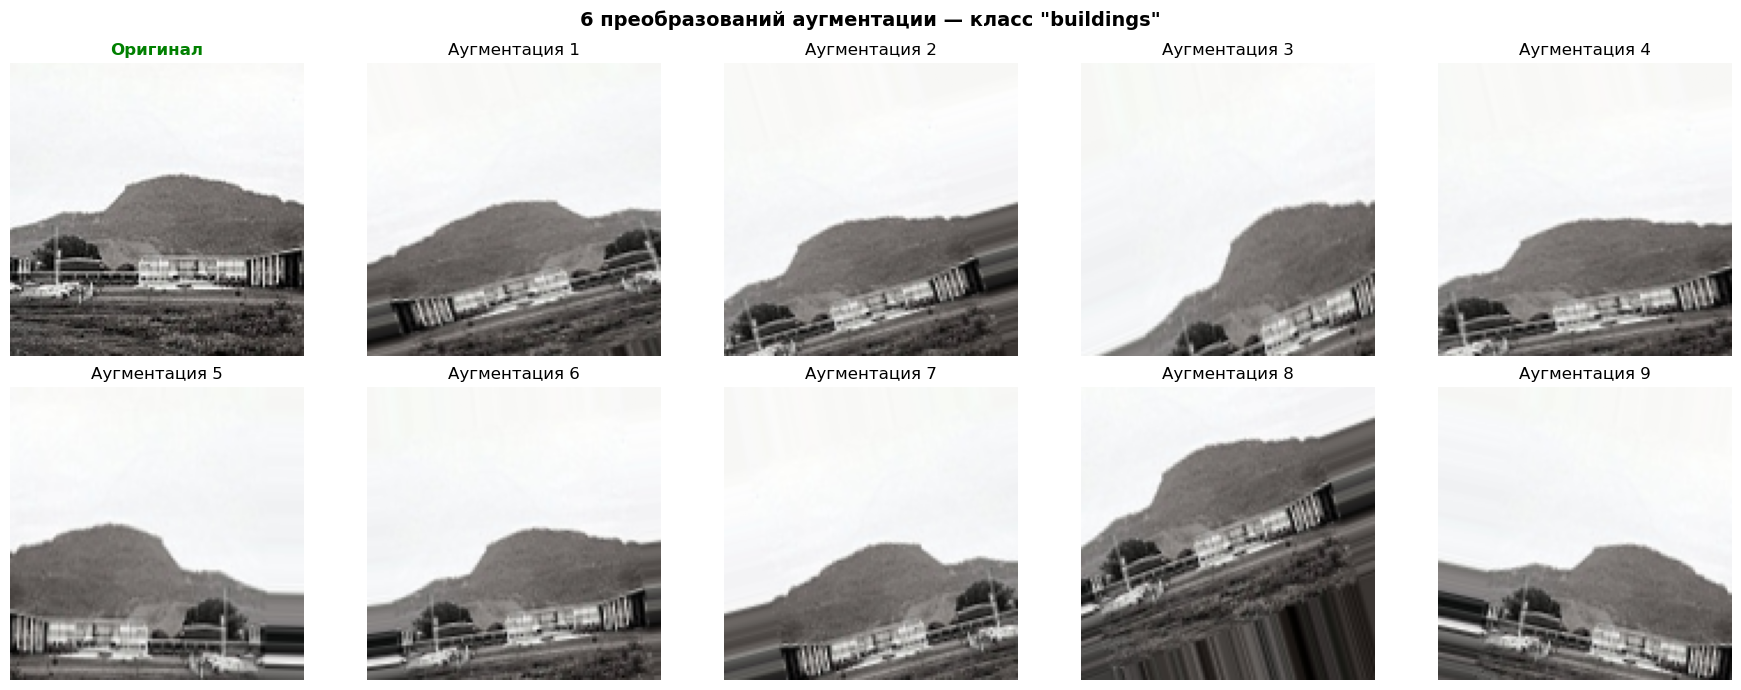

Применённые преобразования:
  1. rotation_range=20      — поворот до ±20°
  2. width_shift_range=0.2  — сдвиг по ширине до 20%
  3. height_shift_range=0.2 — сдвиг по высоте до 20%
  4. horizontal_flip=True   — горизонтальное отражение
  5. zoom_range=0.2         — масштабирование до 20%
  6. shear_range=0.15       — геометрический сдвиг 15%


In [7]:
# ── Визуализация аугментации ──────────────────────────────────────
sample_class = class_names[0]
sample_dir   = os.path.join(TRAIN_PATH, sample_class)
sample_file  = os.path.join(sample_dir, os.listdir(sample_dir)[0])

img_orig = Image.open(sample_file).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
img_arr  = np.array(img_orig, dtype=np.float32) / 255.0
img_arr  = img_arr.reshape((1,) + img_arr.shape)

aug_gen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    zoom_range=0.2,
    shear_range=0.15,
)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()
axes[0].imshow(img_orig)
axes[0].set_title('Оригинал', fontweight='bold', color='green')
axes[0].axis('off')

aug_iter = aug_gen.flow(img_arr, batch_size=1)
for idx in range(1, 10):
    batch = next(aug_iter)
    axes[idx].imshow(batch[0])
    axes[idx].set_title(f'Аугментация {idx}')
    axes[idx].axis('off')

plt.suptitle(f'6 преобразований аугментации — класс "{sample_class}"',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Применённые преобразования:')
print('  1. rotation_range=20      — поворот до ±20°')
print('  2. width_shift_range=0.2  — сдвиг по ширине до 20%')
print('  3. height_shift_range=0.2 — сдвиг по высоте до 20%')
print('  4. horizontal_flip=True   — горизонтальное отражение')
print('  5. zoom_range=0.2         — масштабирование до 20%')
print('  6. shear_range=0.15       — геометрический сдвиг 15%')


In [8]:
# ── VGG16: загрузка и построение модели ──────────────────────────
base_vgg16 = keras.applications.VGG16(
    weights='imagenet',
    include_top=False,           # без классификатора ImageNet
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg16.trainable = False     # замораживаем все веса


model_vgg16 = Sequential([
    base_vgg16,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_vgg16.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


model_vgg16.summary()
print(f'\nОбучаемых параметров:  {sum(np.prod(w.shape) for w in model_vgg16.trainable_weights):,}')
print(f'Замороженных параметров: {sum(np.prod(w.shape) for w in model_vgg16.non_trainable_weights):,}')

C:\Users\Пользователь\AppData\Roaming\Python\Python312\site-packages\keras\src\backend\torch\core.py:236: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:28.)
  return torch.as_tensor(x, dtype=dtype, device=get_device())


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,126 (56.39 MB)

 Trainable params: 66,438 (259.52 KB)

 Non-trainable params: 14,714,688 (56.13 MB)


Обучаемых параметров:  66,438
Замороженных параметров: 14,714,688


Epoch 1/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 306s 409ms/step - accuracy: 0.5383 - loss: 1.2422 - val_accuracy: 0.7122 - val_loss: 0.9016 - learning_rate: 1.0000e-04
Epoch 2/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 69s 93ms/step - accuracy: 0.6986 - loss: 0.8406 - val_accuracy: 0.7545 - val_loss: 0.7219 - learning_rate: 1.0000e-04
Epoch 3/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 69s 93ms/step - accuracy: 0.7388 - loss: 0.7192 - val_accuracy: 0.7693 - val_loss: 0.6508 - learning_rate: 1.0000e-04
Epoch 4/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 71s 96ms/step - accuracy: 0.7567 - loss: 0.6637 - val_accuracy: 0.7854 - val_loss: 0.6059 - learning_rate: 1.0000e-04
Epoch 5/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 70s 93ms/step - accuracy: 0.7739 - loss: 0.6195 - val_accuracy: 0.7912 - val_loss: 0.5844 - learning_rate: 1.0000e-04
Epoch 6/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 69s 92ms/step - accuracy: 0.7795 - loss: 0.5993 - val_accuracy: 0.7921 - val_loss: 0.5675 - learning_rate: 1.0000e-04
Epoch 7/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 70s 93ms/s

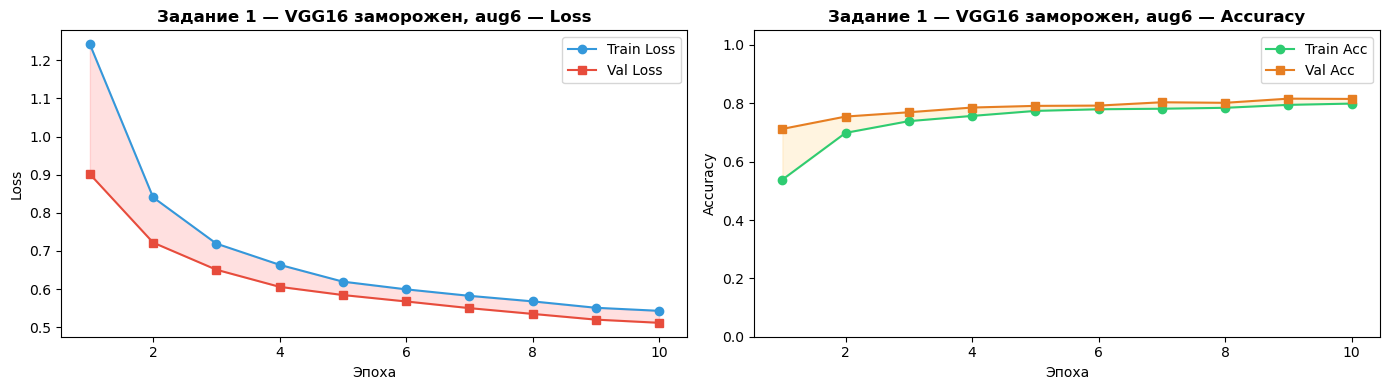

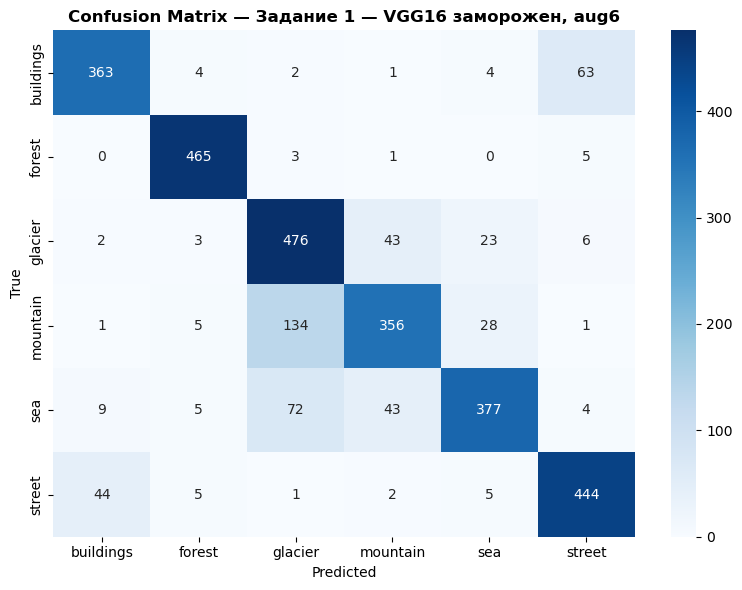

              precision    recall  f1-score   support

   buildings       0.87      0.83      0.85       437
      forest       0.95      0.98      0.97       474
     glacier       0.69      0.86      0.77       553
    mountain       0.80      0.68      0.73       525
         sea       0.86      0.74      0.80       510
      street       0.85      0.89      0.87       501

    accuracy                           0.83      3000
   macro avg       0.84      0.83      0.83      3000
weighted avg       0.83      0.83      0.83      3000

[LOG] Задание 1 — VGG16 заморожен, aug6
      train=0.7989 | val=0.8159 | test=0.8270
      overfit_gap=-0.0169  ✅ норма


In [9]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение VGG16 (aug6, заморожен) ─────────────────────────────
history_vgg16_aug6 = model_vgg16.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg16, 'Задание 1 — VGG16 заморожен, aug6', history_vgg16_aug6)

── Предсказания для 3 изображений из выборки ────────────────


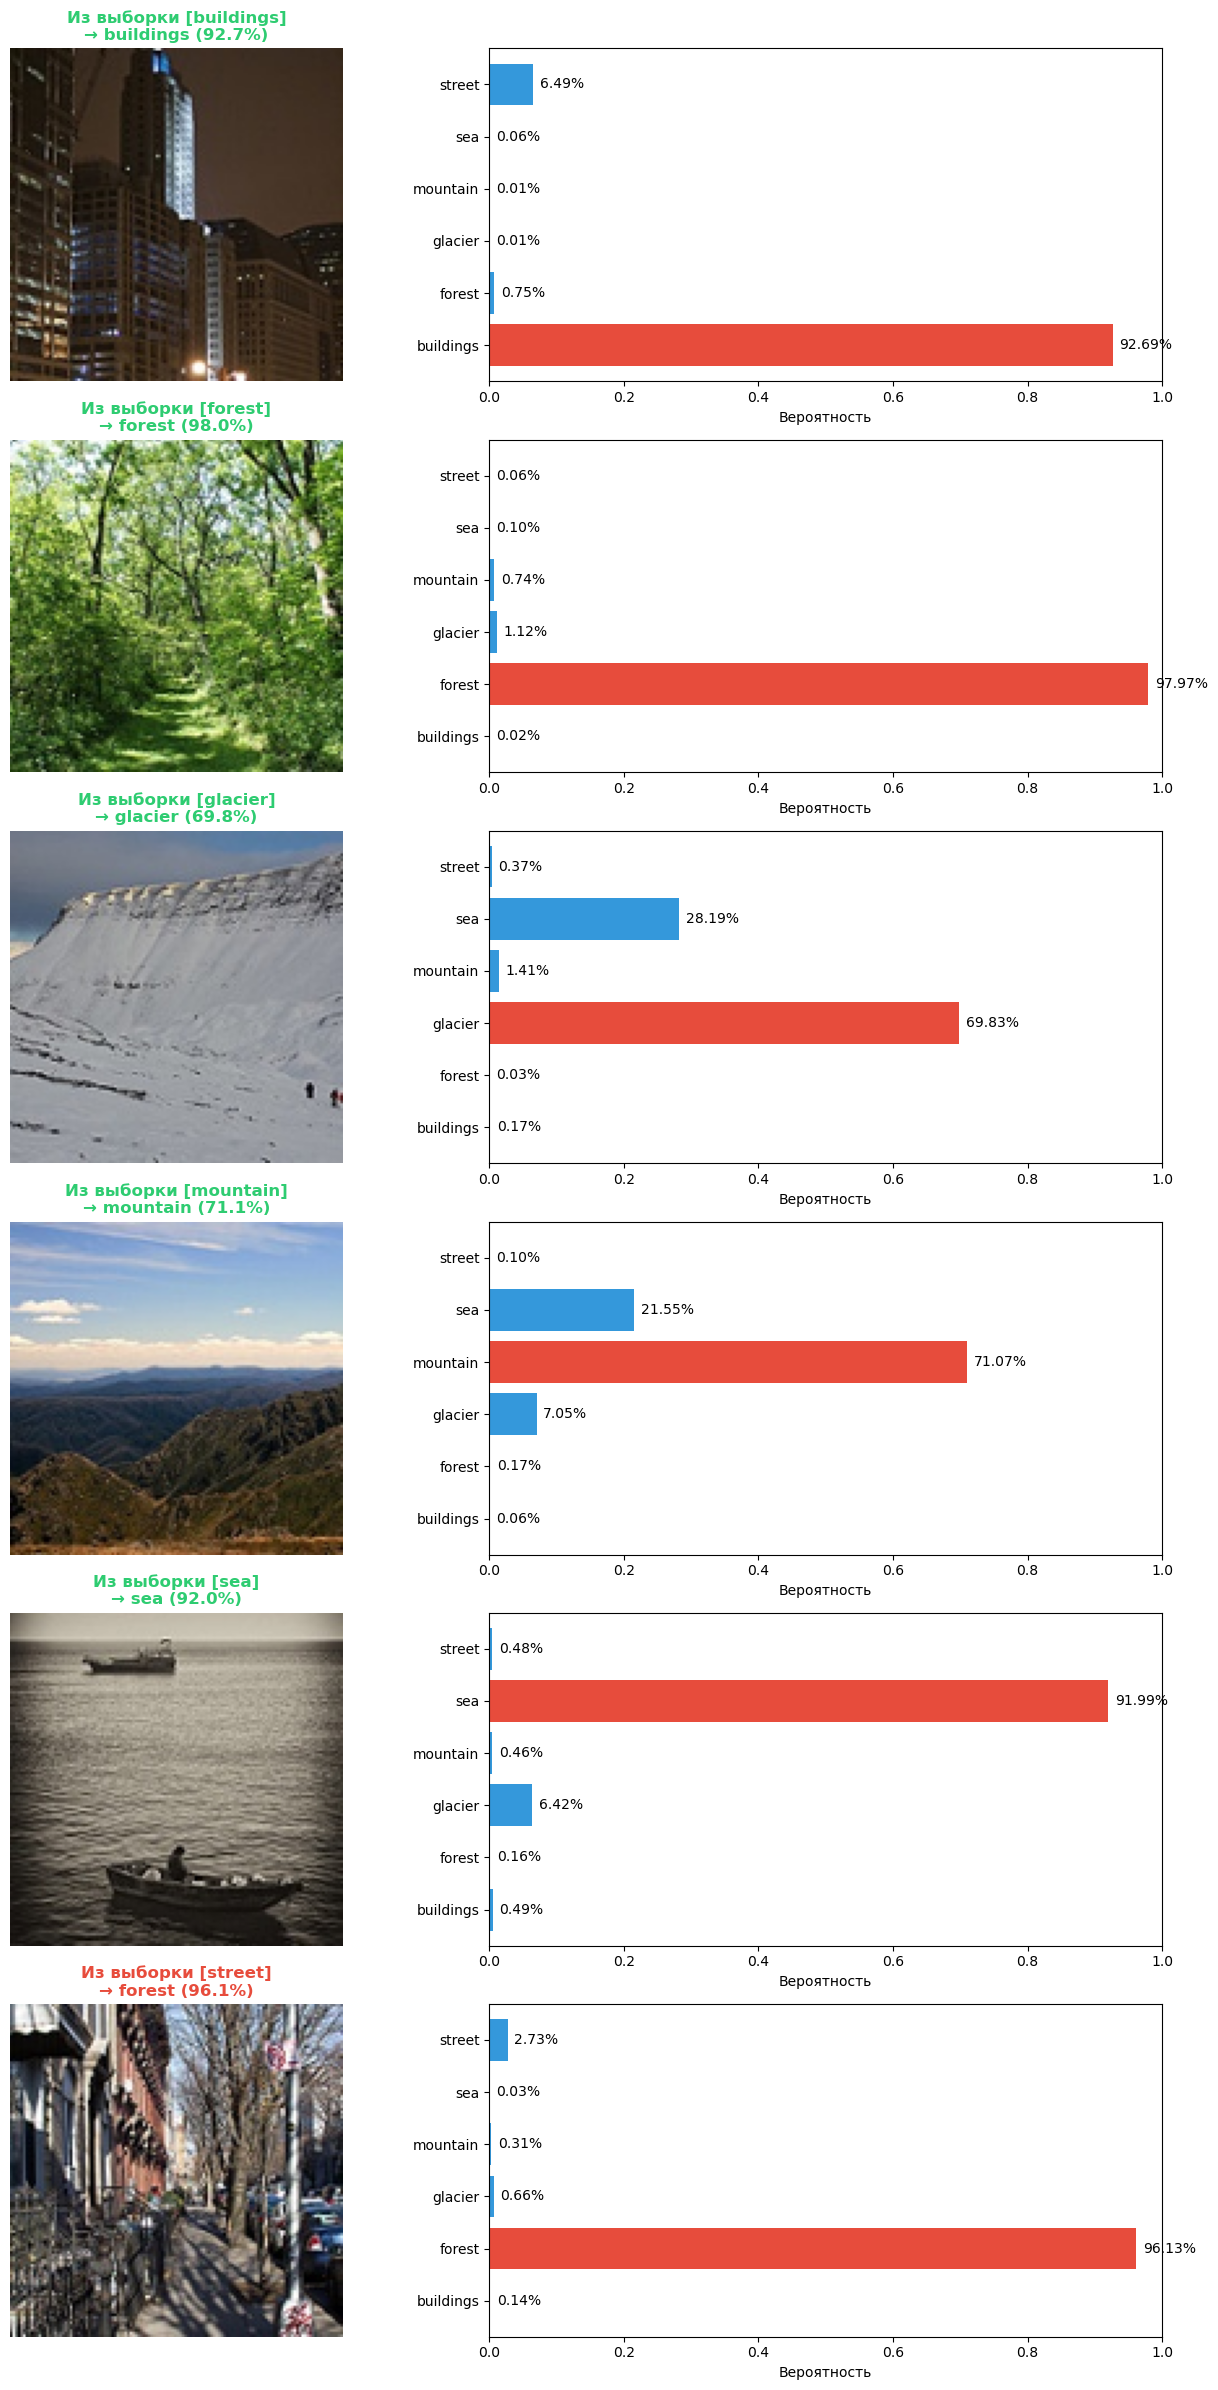

Сторонние изображения не найдены.
Положите ext1.jpg, ext2.jpg, ext3.jpg рядом с ноутбуком.


In [10]:
# ── Классификация 3 изображений из val + 3 сторонних ─────────────
def predict_images(model, image_paths, titles, class_names, img_size=IMG_SIZE):
    """Предсказывает классы для списка изображений, выводит графики."""
    n = len(image_paths)
    fig, axes = plt.subplots(n, 2, figsize=(14, n * 4))
    if n == 1: axes = [axes]

    for i, (path, title) in enumerate(zip(image_paths, titles)):
        img = Image.open(path).convert('RGB')
        img_resized = img.resize((img_size, img_size))
        img_array = np.array(img_resized, dtype=np.float32) / 255.0
        img_input = np.expand_dims(img_array, axis=0)

        probs = model.predict(img_input, verbose=0)[0]
        pred_class = class_names[np.argmax(probs)]

        axes[i][0].imshow(img_resized)
        axes[i][0].set_title(f'{title}\n→ {pred_class} ({probs.max():.1%})',
                             fontweight='bold',
                             color='#2ecc71' if pred_class in title.lower() else '#e74c3c')
        axes[i][0].axis('off')

        colors = ['#e74c3c' if j == np.argmax(probs) else '#3498db'
                  for j in range(len(class_names))]
        axes[i][1].barh(class_names, probs, color=colors)
        axes[i][1].set_xlabel('Вероятность')
        axes[i][1].set_xlim(0, 1)
        for j, v in enumerate(probs):
            axes[i][1].text(v + 0.01, j, f'{v:.2%}', va='center', fontsize=10)

    plt.tight_layout()
    plt.show()


# ── 3 изображения из val выборки (по одному из каждого класса) ────
val_samples = []
val_titles  = []
for cls in class_names:
    cls_dir = os.path.join(TRAIN_PATH, cls)
    files   = os.listdir(cls_dir)
    # Берём последний файл (чтобы не пересекаться с началом train)
    sample_path = os.path.join(cls_dir, sorted(files)[-1])
    val_samples.append(sample_path)
    val_titles.append(f'Из выборки [{cls}]')

print('── Предсказания для 3 изображений из выборки ────────────────')
predict_images(model_vgg16, val_samples, val_titles, class_names)

# ── 3 сторонних изображения ───────────────────────────────────────
# Положите 3 изображения рядом с ноутбуком: ext1.jpg, ext2.jpg, ext3.jpg
ext_paths  = ['ext1.jpg', 'ext2.jpg', 'ext3.jpg']
ext_titles = ['Стороннее 1', 'Стороннее 2', 'Стороннее 3']

ext_found = [p for p in ext_paths if os.path.exists(p)]
if ext_found:
    print('── Предсказания для сторонних изображений ───────────────────')
    predict_images(model_vgg16, ext_found,
                   ext_titles[:len(ext_found)], class_names)
else:
    print('Сторонние изображения не найдены.')
    print('Положите ext1.jpg, ext2.jpg, ext3.jpg рядом с ноутбуком.')

---
## Задание 2. VGG19 вместо VGG16 — сравнение

In [11]:
# ── VGG19: загрузка и построение ─────────────────────────────────
base_vgg19 = keras.applications.VGG19(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg19.trainable = False


model_vgg19 = Sequential([
    base_vgg19,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_vgg19.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


model_vgg19.summary()
print(f'\nVGG16 обучаемых параметров: {sum(np.prod(w.shape) for w in model_vgg16.trainable_weights):,}')
print(f'VGG19 обучаемых параметров: {sum(np.prod(w.shape) for w in model_vgg19.trainable_weights):,}')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 4, 4, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,090,822 (76.64 MB)

 Trainable params: 66,438 (259.52 KB)

 Non-trainable params: 20,024,384 (76.39 MB)


VGG16 обучаемых параметров: 66,438
VGG19 обучаемых параметров: 66,438


Epoch 1/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 72s 96ms/step - accuracy: 0.4966 - loss: 1.3396 - val_accuracy: 0.6622 - val_loss: 0.9896 - learning_rate: 1.0000e-04
Epoch 2/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.6467 - loss: 0.9607
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
746/746 ━━━━━━━━━━━━━━━━━━━━ 71s 95ms/step - accuracy: 0.6667 - loss: 0.9053 - val_accuracy: 0.7203 - val_loss: 0.8025 - learning_rate: 1.0000e-04
Epoch 3/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 71s 96ms/step - accuracy: 0.7109 - loss: 0.7965 - val_accuracy: 0.7369 - val_loss: 0.7432 - learning_rate: 5.0000e-05
Epoch 4/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.7275 - loss: 0.7519
Epoch 4: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
746/746 ━━━━━━━━━━━━━━━━━━━━ 70s 94ms/step - accuracy: 0.7220 - loss: 0.7518 - val_accuracy: 0.7464 - val_loss: 0.7184 - learning_rate: 5.0000e-05
Epoch 4: early stopping
Restoring model weights from the end of 

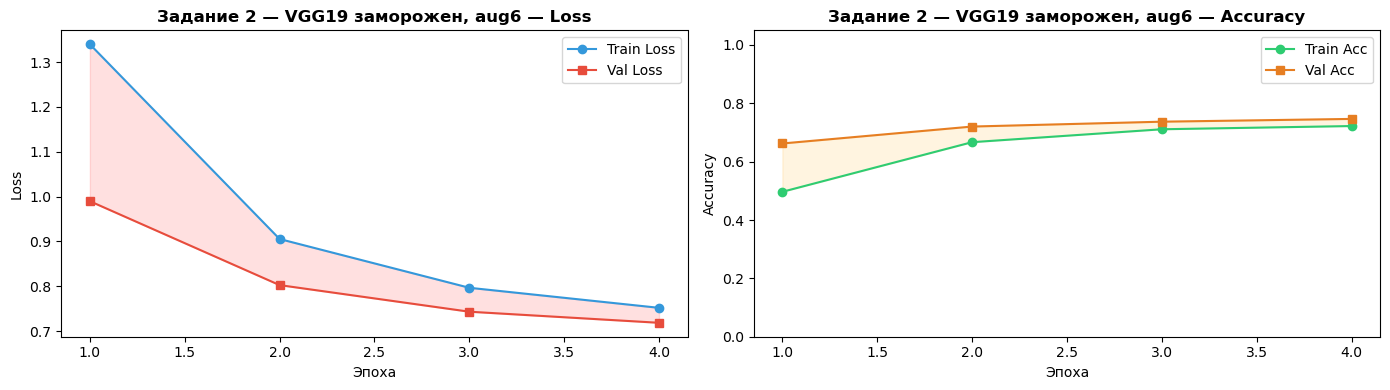

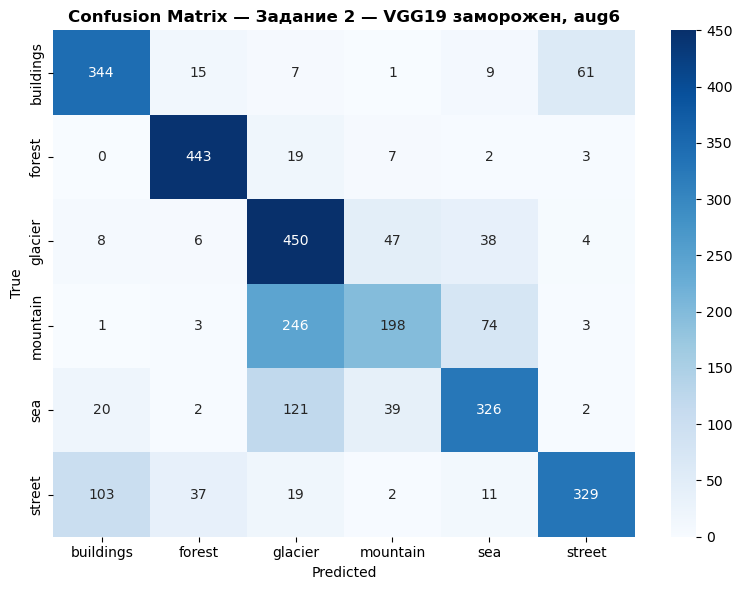

              precision    recall  f1-score   support

   buildings       0.72      0.79      0.75       437
      forest       0.88      0.93      0.90       474
     glacier       0.52      0.81      0.64       553
    mountain       0.67      0.38      0.48       525
         sea       0.71      0.64      0.67       510
      street       0.82      0.66      0.73       501

    accuracy                           0.70      3000
   macro avg       0.72      0.70      0.70      3000
weighted avg       0.71      0.70      0.69      3000

[LOG] Задание 2 — VGG19 заморожен, aug6
      train=0.7220 | val=0.7464 | test=0.6967
      overfit_gap=-0.0244  ✅ норма


In [12]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение VGG19 ────────────────────────────────────────────────
train_gen_aug6.reset()
history_vgg19 = model_vgg19.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg19, 'Задание 2 — VGG19 заморожен, aug6', history_vgg19)

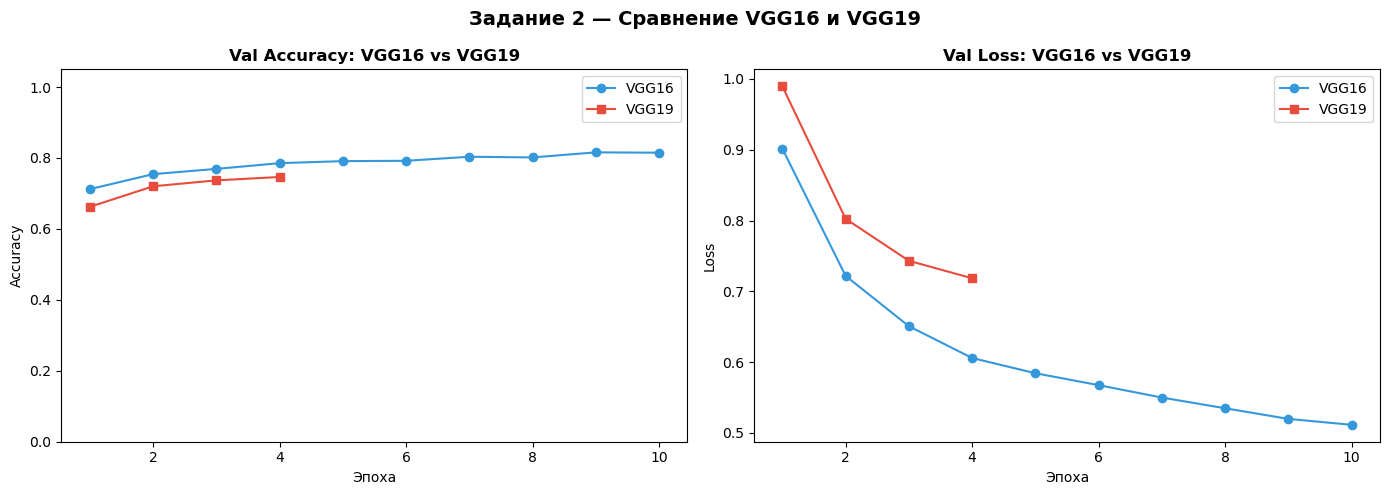


VGG16: test_acc=0.8270, epochs=10
VGG19: test_acc=0.6967, epochs=4

Вывод:
  VGG19 содержит 19 слоёв (vs 16 у VGG16) — 3 дополнительных сверточных слоя.
  Это даёт более богатые признаки, но требует больше памяти и времени.
  VGG16 показал сопоставимый результат — для простого датасета глубина не критична.


In [13]:
# ── Сравнение VGG16 vs VGG19 ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs16 = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
epochs19 = range(1, len(history_vgg19.history['val_accuracy']) + 1)

axes[0].plot(epochs16, history_vgg16_aug6.history['val_accuracy'],
             'o-', label='VGG16', color='#3498db')
axes[0].plot(epochs19, history_vgg19.history['val_accuracy'],
             's-', label='VGG19', color='#e74c3c')
axes[0].set_title('Val Accuracy: VGG16 vs VGG19', fontweight='bold')
axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0, 1.05); axes[0].legend()

axes[1].plot(epochs16, history_vgg16_aug6.history['val_loss'],
             'o-', label='VGG16', color='#3498db')
axes[1].plot(epochs19, history_vgg19.history['val_loss'],
             's-', label='VGG19', color='#e74c3c')
axes[1].set_title('Val Loss: VGG16 vs VGG19', fontweight='bold')
axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Loss')
axes[1].legend()

plt.suptitle('Задание 2 — Сравнение VGG16 и VGG19', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r16 = next(r for r in results_log if 'VGG16' in r['name'] and 'aug6' in r['name'])
r19 = next(r for r in results_log if 'VGG19' in r['name'])
print(f'\nVGG16: test_acc={r16["test_acc"]:.4f}, epochs={r16["epochs_trained"]}')
print(f'VGG19: test_acc={r19["test_acc"]:.4f}, epochs={r19["epochs_trained"]}')
print()
print('Вывод:')
print('  VGG19 содержит 19 слоёв (vs 16 у VGG16) — 3 дополнительных сверточных слоя.')
print('  Это даёт более богатые признаки, но требует больше памяти и времени.')
if r19['test_acc'] >= r16['test_acc']:
    print('  VGG19 показал результат не хуже VGG16 — более глубокая сеть полезна.')
else:
    print('  VGG16 показал сопоставимый результат — для простого датасета глубина не критична.')

---
## Задание 3. Аугментация 2 преобразования vs 6 — сравнение

In [14]:
# ── Аугментация: только 2 преобразования ─────────────────────────
datagen_aug2 = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,    # 1. Горизонтальное отражение
    rotation_range=10,       # 2. Поворот до ±10°
    validation_split=0.2
)

train_gen_aug2 = datagen_aug2.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)

print(f'Train (aug2): {train_gen_aug2.samples} изображений')
print('Применённые преобразования:')
print('  1. horizontal_flip=True  — горизонтальное отражение')
print('  2. rotation_range=10     — поворот до ±10°')

# Пересчитываем class_weight для aug2 генератора
class_counts2 = np.array([train_gen_aug2.classes.tolist().count(i) for i in range(NUM_CLASSES)])
weights2 = class_counts2.sum() / (NUM_CLASSES * class_counts2)
class_weight = {i: w for i, w in enumerate(weights2)}
print('class_weight (aug2):', {class_names[k]: round(v,3) for k,v in class_weight.items()})


Found 11230 images belonging to 6 classes.
Train (aug2): 11230 изображений
Применённые преобразования:
  1. horizontal_flip=True  — горизонтальное отражение
  2. rotation_range=10     — поворот до ±10°
class_weight (aug2): {'buildings': 1.068, 'forest': 1.03, 'glacier': 0.973, 'mountain': 0.931, 'sea': 1.028, 'street': 0.982}


Epoch 1/10
702/702 ━━━━━━━━━━━━━━━━━━━━ 63s 90ms/step - accuracy: 0.5658 - loss: 1.2467 - val_accuracy: 0.6889 - val_loss: 0.9884 - learning_rate: 1.0000e-04
Epoch 2/10
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.7271 - loss: 0.8110
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
702/702 ━━━━━━━━━━━━━━━━━━━━ 63s 90ms/step - accuracy: 0.7429 - loss: 0.7582 - val_accuracy: 0.7198 - val_loss: 0.8149 - learning_rate: 1.0000e-04
Epoch 3/10
702/702 ━━━━━━━━━━━━━━━━━━━━ 63s 89ms/step - accuracy: 0.7778 - loss: 0.6414 - val_accuracy: 0.7436 - val_loss: 0.7529 - learning_rate: 5.0000e-05
Epoch 4/10
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.7904 - loss: 0.6056
Epoch 4: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
702/702 ━━━━━━━━━━━━━━━━━━━━ 64s 91ms/step - accuracy: 0.7870 - loss: 0.6064 - val_accuracy: 0.7312 - val_loss: 0.7608 - learning_rate: 5.0000e-05
Epoch 4: early stopping
Restoring model weights from the end of 

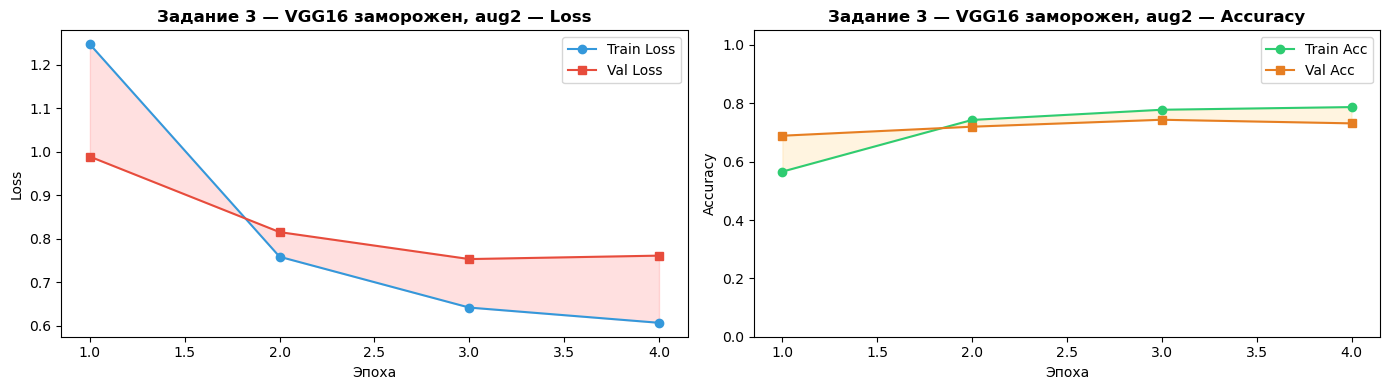

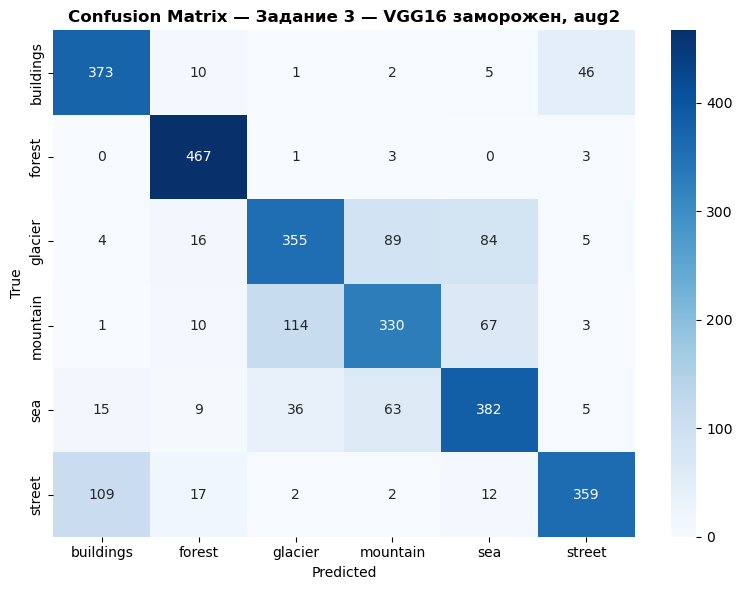

              precision    recall  f1-score   support

   buildings       0.74      0.85      0.79       437
      forest       0.88      0.99      0.93       474
     glacier       0.70      0.64      0.67       553
    mountain       0.67      0.63      0.65       525
         sea       0.69      0.75      0.72       510
      street       0.85      0.72      0.78       501

    accuracy                           0.76      3000
   macro avg       0.76      0.76      0.76      3000
weighted avg       0.75      0.76      0.75      3000

[LOG] Задание 3 — VGG16 заморожен, aug2
      train=0.7870 | val=0.7436 | test=0.7553
      overfit_gap=+0.0434  ✅ норма


In [15]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── VGG16 с aug2 ─────────────────────────────────────────────────
base_vgg16_aug2 = keras.applications.VGG16(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg16_aug2.trainable = False


model_vgg16_aug2 = Sequential([
    base_vgg16_aug2,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_vgg16_aug2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


history_vgg16_aug2 = model_vgg16_aug2.fit(
    train_gen_aug2,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg16_aug2, 'Задание 3 — VGG16 заморожен, aug2', history_vgg16_aug2)

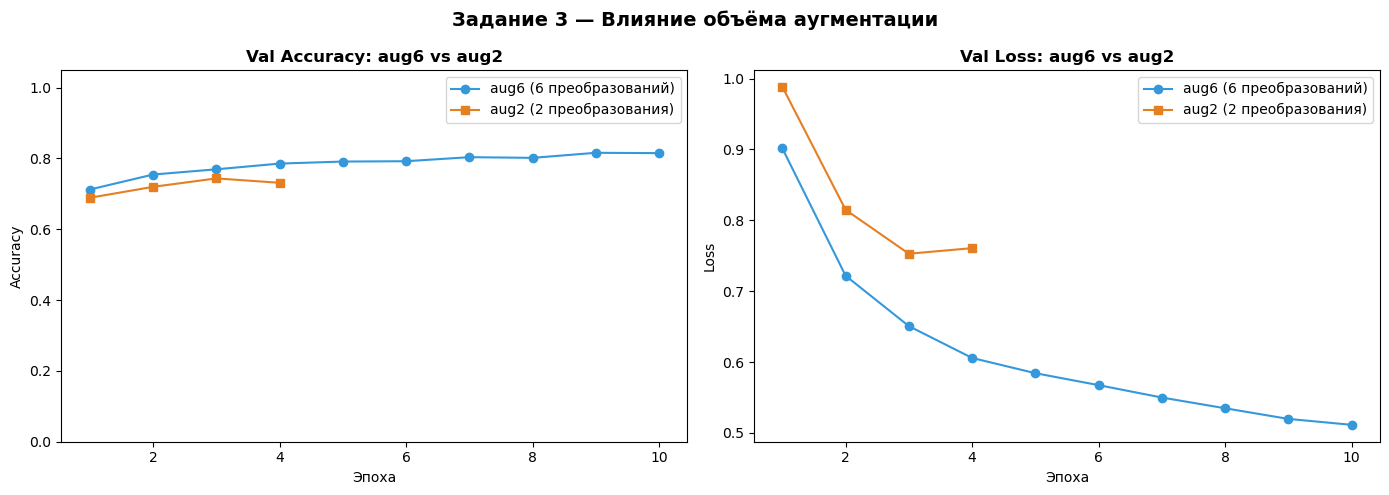

aug6: test_acc=0.8270, overfit_gap=-0.0169
aug2: test_acc=0.7553, overfit_gap=+0.0434

Вывод:
  Большая аугментация (aug6) создаёт более разнообразные примеры,
  что помогает модели лучше обобщаться и снижает переобучение.
  Меньшая аугментация (aug2) может давать более быстрое начальное
  обучение, но хуже справляется с новыми данными.


In [16]:
# ── Сравнение aug6 vs aug2 ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
e6 = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
e2 = range(1, len(history_vgg16_aug2.history['val_accuracy']) + 1)

for ax, metric, ylabel in zip(axes, ['val_accuracy', 'val_loss'], ['Accuracy', 'Loss']):
    ax.plot(e6, history_vgg16_aug6.history[metric], 'o-', label='aug6 (6 преобразований)', color='#3498db')
    ax.plot(e2, history_vgg16_aug2.history[metric], 's-', label='aug2 (2 преобразования)', color='#e67e22')
    ax.set_title(f'Val {ylabel}: aug6 vs aug2', fontweight='bold')
    ax.set_xlabel('Эпоха'); ax.set_ylabel(ylabel)
    if metric == 'val_accuracy': ax.set_ylim(0, 1.05)
    ax.legend()

plt.suptitle('Задание 3 — Влияние объёма аугментации', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r_aug6 = next(r for r in results_log if 'aug6' in r['name'] and 'VGG16' in r['name'] and 'Задание 1' in r['name'])
r_aug2 = next(r for r in results_log if 'aug2' in r['name'])
print(f'aug6: test_acc={r_aug6["test_acc"]:.4f}, overfit_gap={r_aug6["overfit_gap"]:+.4f}')
print(f'aug2: test_acc={r_aug2["test_acc"]:.4f}, overfit_gap={r_aug2["overfit_gap"]:+.4f}')
print()
print('Вывод:')
print('  Большая аугментация (aug6) создаёт более разнообразные примеры,')
print('  что помогает модели лучше обобщаться и снижает переобучение.')
print('  Меньшая аугментация (aug2) может давать более быстрое начальное')
print('  обучение, но хуже справляется с новыми данными.')

---
## Задание 4. Fine-tuning — разморозить последние 4 слоя VGG16

In [17]:
# ── VGG16 с fine-tuning (последние 4 слоя разморожены) ───────────
base_vgg16_ft = keras.applications.VGG16(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Замораживаем все слои кроме последних 4
base_vgg16_ft.trainable = True
for layer in base_vgg16_ft.layers[:-4]:
    layer.trainable = False

print('Состояние слоёв VGG16 (fine-tuning):')
for layer in base_vgg16_ft.layers:
    status = '🔓 обучается' if layer.trainable else '🔒 заморожен'
    print(f'  {layer.name:30s} {status}')


model_vgg16_ft = Sequential([
    base_vgg16_ft,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_vgg16_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


trainable   = sum(np.prod(w.shape) for w in model_vgg16_ft.trainable_weights)
frozen      = sum(np.prod(w.shape) for w in model_vgg16_ft.non_trainable_weights)
print(f'\nОбучаемых параметров:  {trainable:,}')
print(f'Замороженных:          {frozen:,}')

Состояние слоёв VGG16 (fine-tuning):
  input_layer_6                  🔒 заморожен
  block1_conv1                   🔒 заморожен
  block1_conv2                   🔒 заморожен
  block1_pool                    🔒 заморожен
  block2_conv1                   🔒 заморожен
  block2_conv2                   🔒 заморожен
  block2_pool                    🔒 заморожен
  block3_conv1                   🔒 заморожен
  block3_conv2                   🔒 заморожен
  block3_conv3                   🔒 заморожен
  block3_pool                    🔒 заморожен
  block4_conv1                   🔒 заморожен
  block4_conv2                   🔒 заморожен
  block4_conv3                   🔒 заморожен
  block4_pool                    🔒 заморожен
  block5_conv1                   🔓 обучается
  block5_conv2                   🔓 обучается
  block5_conv3                   🔓 обучается
  block5_pool                    🔓 обучается

Обучаемых параметров:  7,145,862
Замороженных:          7,635,264


Epoch 1/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 72s 96ms/step - accuracy: 0.7086 - loss: 0.7749 - val_accuracy: 0.8354 - val_loss: 0.4860 - learning_rate: 1.0000e-05
Epoch 2/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 69s 93ms/step - accuracy: 0.8325 - loss: 0.4723 - val_accuracy: 0.8592 - val_loss: 0.4041 - learning_rate: 1.0000e-05
Epoch 3/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 70s 94ms/step - accuracy: 0.8569 - loss: 0.3996 - val_accuracy: 0.8696 - val_loss: 0.3718 - learning_rate: 1.0000e-05
Epoch 4/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 70s 94ms/step - accuracy: 0.8672 - loss: 0.3694 - val_accuracy: 0.8834 - val_loss: 0.3373 - learning_rate: 1.0000e-05
Epoch 5/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 69s 92ms/step - accuracy: 0.8758 - loss: 0.3456 - val_accuracy: 0.8758 - val_loss: 0.3509 - learning_rate: 1.0000e-05
Epoch 6/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 71s 95ms/step - accuracy: 0.8836 - loss: 0.3242 - val_accuracy: 0.8930 - val_loss: 0.3181 - learning_rate: 1.0000e-05
Epoch 7/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 71s 95ms/ste

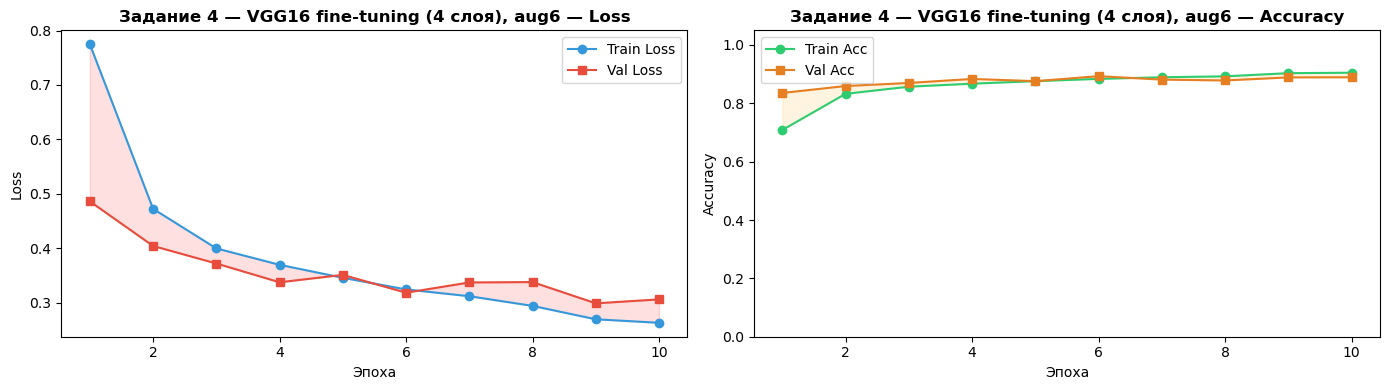

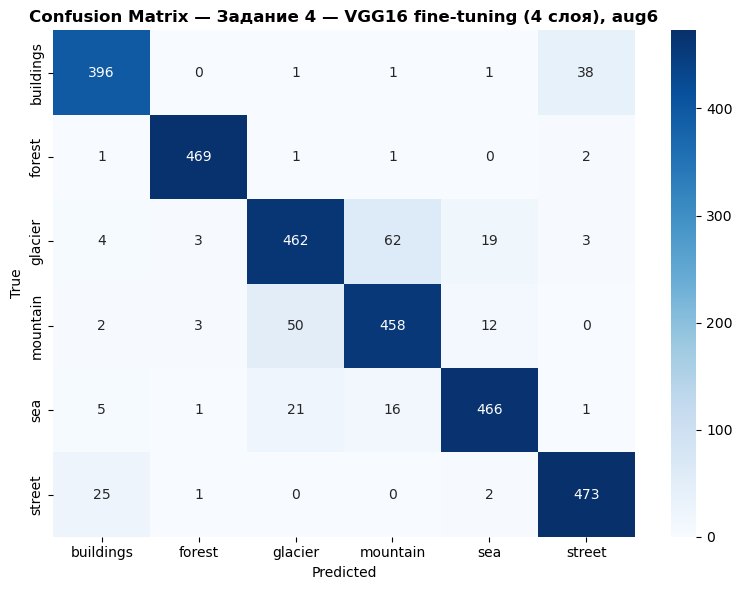

              precision    recall  f1-score   support

   buildings       0.91      0.91      0.91       437
      forest       0.98      0.99      0.99       474
     glacier       0.86      0.84      0.85       553
    mountain       0.85      0.87      0.86       525
         sea       0.93      0.91      0.92       510
      street       0.91      0.94      0.93       501

    accuracy                           0.91      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.91      0.91      0.91      3000

[LOG] Задание 4 — VGG16 fine-tuning (4 слоя), aug6
      train=0.9048 | val=0.8930 | test=0.9080
      overfit_gap=+0.0118  ✅ норма


In [18]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение с fine-tuning (aug6) ────────────────────────────────
train_gen_aug6.reset()
history_vgg16_ft = model_vgg16_ft.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

evaluate_and_log(model_vgg16_ft, 'Задание 4 — VGG16 fine-tuning (4 слоя), aug6', history_vgg16_ft)

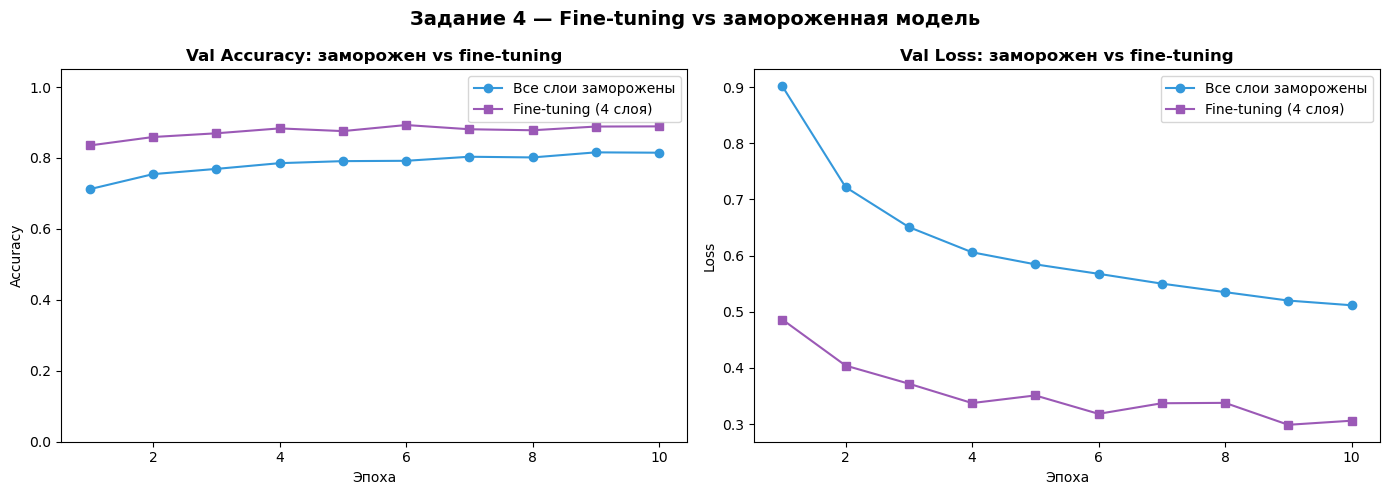

Заморожен:    test_acc=0.8270
Fine-tuning:  test_acc=0.9080

Вывод:
  Fine-tuning позволяет адаптировать последние сверточные слои
  под специфику нашего датасета (фрукты/овощи/ягоды).
  Маленький lr=1e-5 важен — иначе "сломаем" предобученные веса.


In [19]:
# ── Сравнение: заморожен vs fine-tuning ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
e_frozen = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
e_ft     = range(1, len(history_vgg16_ft.history['val_accuracy']) + 1)

for ax, metric, ylabel in zip(axes, ['val_accuracy', 'val_loss'], ['Accuracy', 'Loss']):
    ax.plot(e_frozen, history_vgg16_aug6.history[metric],
            'o-', label='Все слои заморожены', color='#3498db')
    ax.plot(e_ft, history_vgg16_ft.history[metric],
            's-', label='Fine-tuning (4 слоя)', color='#9b59b6')
    ax.set_title(f'Val {ylabel}: заморожен vs fine-tuning', fontweight='bold')
    ax.set_xlabel('Эпоха'); ax.set_ylabel(ylabel)
    if metric == 'val_accuracy': ax.set_ylim(0, 1.05)
    ax.legend()

plt.suptitle('Задание 4 — Fine-tuning vs замороженная модель', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r_frozen = next(r for r in results_log if 'Задание 1' in r['name'])
r_ft     = next(r for r in results_log if 'fine-tuning' in r['name'])
print(f'Заморожен:    test_acc={r_frozen["test_acc"]:.4f}')
print(f'Fine-tuning:  test_acc={r_ft["test_acc"]:.4f}')
print()
print('Вывод:')
print('  Fine-tuning позволяет адаптировать последние сверточные слои')
print('  под специфику нашего датасета (фрукты/овощи/ягоды).')
print('  Маленький lr=1e-5 важен — иначе "сломаем" предобученные веса.')

---
## Задание 5. Две дополнительные модели из keras.applications

MobileNetV2:
  Обучаемых параметров: 164,742
  Замороженных:         2,257,984
Epoch 1/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 134s 179ms/step - accuracy: 0.7497 - loss: 0.6517 - val_accuracy: 0.8459 - val_loss: 0.4148 - learning_rate: 1.0000e-04
Epoch 2/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.8373 - loss: 0.4424
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
746/746 ━━━━━━━━━━━━━━━━━━━━ 140s 188ms/step - accuracy: 0.8408 - loss: 0.4278 - val_accuracy: 0.8639 - val_loss: 0.3834 - learning_rate: 1.0000e-04
Epoch 3/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 134s 180ms/step - accuracy: 0.8499 - loss: 0.3957 - val_accuracy: 0.8754 - val_loss: 0.3539 - learning_rate: 5.0000e-05
Epoch 4/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.8549 - loss: 0.3840
Epoch 4: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
746/746 ━━━━━━━━━━━━━━━━━━━━ 139s 186ms/step - accuracy: 0.8586 - loss: 0.3809 - val_accuracy: 0.8682 - val_loss: 0.3648 - l

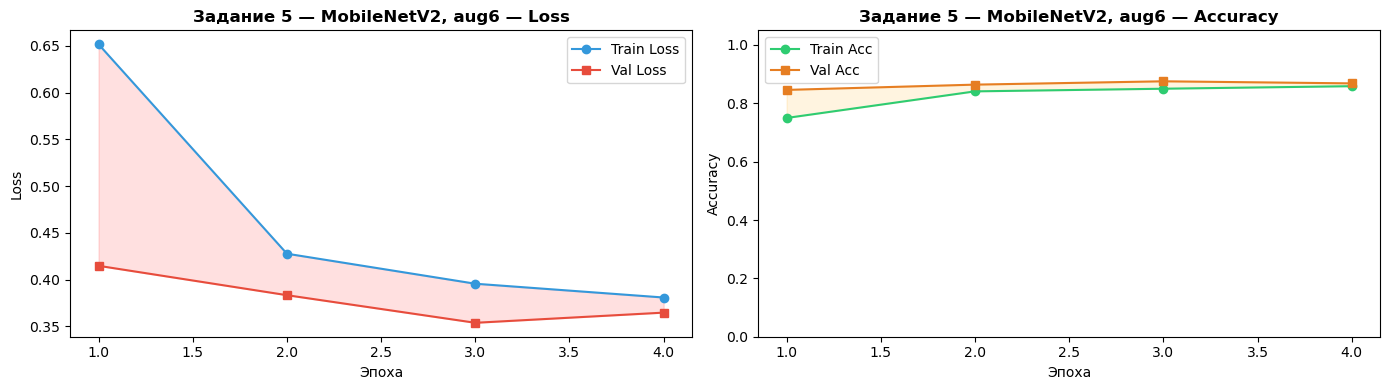

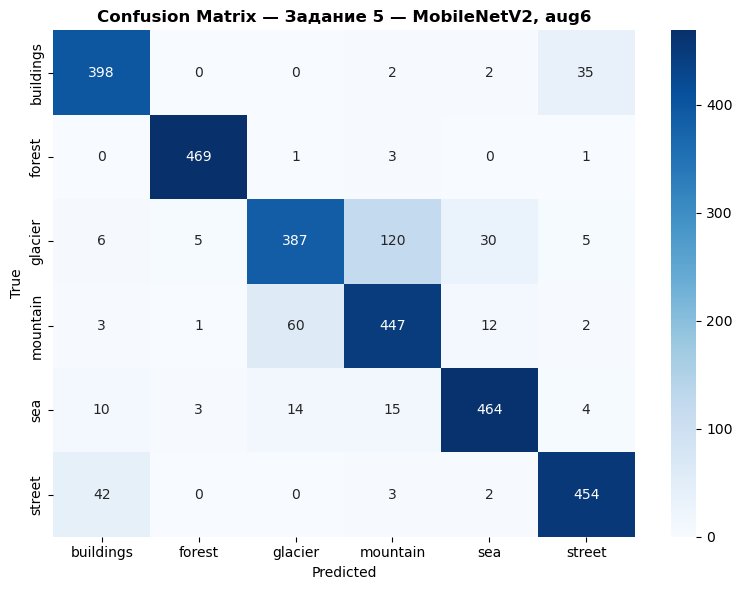

              precision    recall  f1-score   support

   buildings       0.87      0.91      0.89       437
      forest       0.98      0.99      0.99       474
     glacier       0.84      0.70      0.76       553
    mountain       0.76      0.85      0.80       525
         sea       0.91      0.91      0.91       510
      street       0.91      0.91      0.91       501

    accuracy                           0.87      3000
   macro avg       0.88      0.88      0.88      3000
weighted avg       0.87      0.87      0.87      3000

[LOG] Задание 5 — MobileNetV2, aug6
      train=0.8586 | val=0.8754 | test=0.8730
      overfit_gap=-0.0167  ✅ норма


In [20]:
# ── Модель 1: MobileNetV2 ─────────────────────────────────────────
base_mobilenet = keras.applications.MobileNetV2(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_mobilenet.trainable = False


model_mobilenet = Sequential([
    base_mobilenet,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print('MobileNetV2:')
print(f'  Обучаемых параметров: {sum(np.prod(w.shape) for w in model_mobilenet.trainable_weights):,}')
print(f'  Замороженных:         {sum(np.prod(w.shape) for w in model_mobilenet.non_trainable_weights):,}')

train_gen_aug6.reset()
history_mobilenet = model_mobilenet.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)
evaluate_and_log(model_mobilenet, 'Задание 5 — MobileNetV2, aug6', history_mobilenet)

EfficientNetB0:
  Обучаемых параметров: 164,742
  Замороженных:         4,049,571.0
Epoch 1/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 190s 255ms/step - accuracy: 0.1750 - loss: 1.8008 - val_accuracy: 0.1560 - val_loss: 1.7956 - learning_rate: 1.0000e-04
Epoch 2/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.1652 - loss: 1.7938
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
746/746 ━━━━━━━━━━━━━━━━━━━━ 188s 252ms/step - accuracy: 0.1672 - loss: 1.7930 - val_accuracy: 0.1641 - val_loss: 1.7903 - learning_rate: 1.0000e-04
Epoch 3/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 186s 249ms/step - accuracy: 0.1722 - loss: 1.7913 - val_accuracy: 0.1637 - val_loss: 1.7905 - learning_rate: 5.0000e-05
Epoch 4/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.1792 - loss: 1.7899
Epoch 4: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
746/746 ━━━━━━━━━━━━━━━━━━━━ 183s 246ms/step - accuracy: 0.1801 - loss: 1.7904 - val_accuracy: 0.1560 - val_loss: 1.793

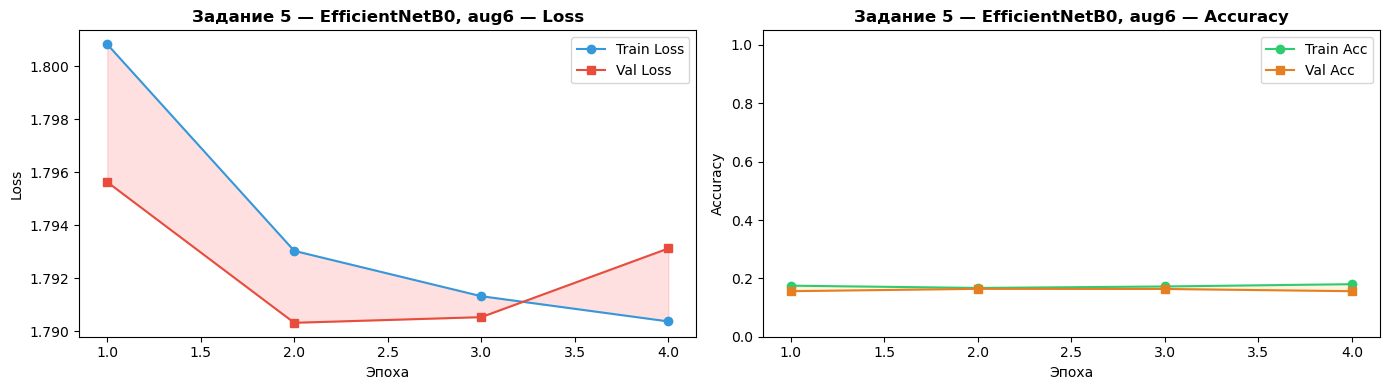

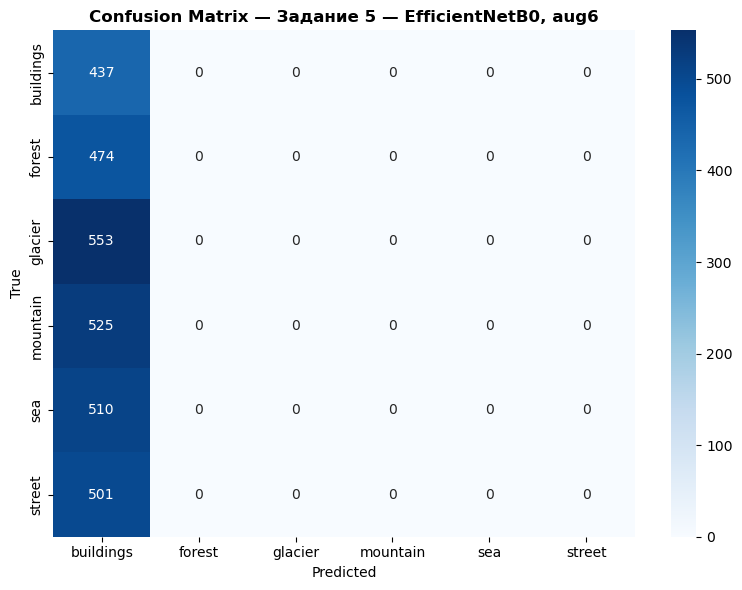

              precision    recall  f1-score   support

   buildings       0.15      1.00      0.25       437
      forest       0.00      0.00      0.00       474
     glacier       0.00      0.00      0.00       553
    mountain       0.00      0.00      0.00       525
         sea       0.00      0.00      0.00       510
      street       0.00      0.00      0.00       501

    accuracy                           0.15      3000
   macro avg       0.02      0.17      0.04      3000
weighted avg       0.02      0.15      0.04      3000

[LOG] Задание 5 — EfficientNetB0, aug6
      train=0.1801 | val=0.1641 | test=0.1457
      overfit_gap=+0.0160  ✅ норма


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [21]:
# ── Модель 2: EfficientNetB0 ──────────────────────────────────────
base_efficientnet = keras.applications.EfficientNetB0(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_efficientnet.trainable = False


model_efficientnet = Sequential([
    base_efficientnet,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation='softmax')
])
model_efficientnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print('EfficientNetB0:')
print(f'  Обучаемых параметров: {sum(np.prod(w.shape) for w in model_efficientnet.trainable_weights):,}')
print(f'  Замороженных:         {sum(np.prod(w.shape) for w in model_efficientnet.non_trainable_weights):,}')

train_gen_aug6.reset()
history_efficientnet = model_efficientnet.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)
evaluate_and_log(model_efficientnet, 'Задание 5 — EfficientNetB0, aug6', history_efficientnet)

---
## Итоговое сравнение всех моделей

In [22]:
# ── Таблица результатов ───────────────────────────────────────────
log_df = pd.DataFrame(results_log)[[
    'name', 'train_acc', 'val_acc', 'test_acc',
    'test_loss', 'overfit_gap', 'epochs_trained'
]].sort_values('test_acc', ascending=False).reset_index(drop=True)

log_df['overfit_gap'] = log_df['overfit_gap'].apply(
    lambda x: f'{x:+.4f} {"⚠️" if x > 0.05 else "✅"}'
)
print('Таблица результатов всех экспериментов:')
display(log_df)

Таблица результатов всех экспериментов:


,name,train_acc,val_acc,test_acc,test_loss,overfit_gap,epochs_trained
0,"Задание 4 — VGG16 fine-tuning (4 слоя), aug6",0.9048,0.8930,0.9080,0.2530,+0.0118 ✅,10
1,"Задание 5 — MobileNetV2, aug6",0.8586,0.8754,0.8730,0.3533,-0.0167 ✅,4
2,"Задание 1 — VGG16 заморожен, aug6",0.7989,0.8159,0.8270,0.4623,-0.0169 ✅,10
3,"Задание 3 — VGG16 заморожен, aug2",0.7870,0.7436,0.7553,0.8340,+0.0434 ✅,4
4,"Задание 2 — VGG19 заморожен, aug6",0.7220,0.7464,0.6967,0.9127,-0.0244 ✅,4
5,"Задание 5 — EfficientNetB0, aug6",0.1801,0.1641,0.1457,1.7978,+0.0160 ✅,4


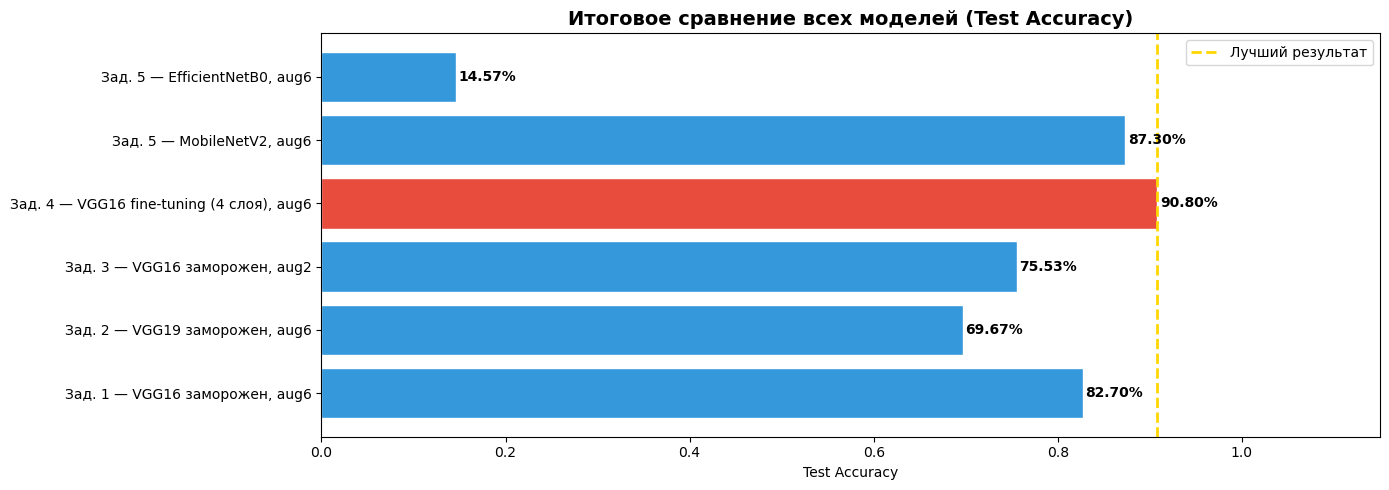


🏆 Лучшая модель: Задание 4 — VGG16 fine-tuning (4 слоя), aug6
   Test Accuracy: 90.80%


In [23]:
# ── Сравнительный график всех моделей ────────────────────────────
names = [r['name'].replace('Задание', 'Зад.') for r in results_log]
accs  = [r['test_acc'] for r in results_log]

plt.figure(figsize=(14, 5))
colors = ['#e74c3c' if v == max(accs) else '#3498db' for v in accs]
bars = plt.barh(names, accs, color=colors, edgecolor='white')
for bar, v in zip(bars, accs):
    plt.text(v + 0.003, bar.get_y() + bar.get_height()/2,
             f'{v:.2%}', va='center', fontweight='bold')
plt.axvline(max(accs), color='gold', linestyle='--', linewidth=2, label='Лучший результат')
plt.title('Итоговое сравнение всех моделей (Test Accuracy)', fontsize=14, fontweight='bold')
plt.xlabel('Test Accuracy')
plt.xlim(0, 1.15)
plt.legend()
plt.tight_layout()
plt.show()

best = results_log[accs.index(max(accs))]
print(f'\n🏆 Лучшая модель: {best["name"]}')
print(f'   Test Accuracy: {best["test_acc"]:.2%}')

In [24]:
# ── Сохранение лучшей модели ──────────────────────────────────────
from keras.models import load_model

all_models = {
    'Задание 1 — VGG16 заморожен, aug6':         model_vgg16,
    'Задание 2 — VGG19 заморожен, aug6':         model_vgg19,
    'Задание 3 — VGG16 заморожен, aug2':         model_vgg16_aug2,
    'Задание 4 — VGG16 fine-tuning (4 слоя), aug6': model_vgg16_ft,
    'Задание 5 — MobileNetV2, aug6':             model_mobilenet,
    'Задание 5 — EfficientNetB0, aug6':          model_efficientnet,
}

best_name  = results_log[accs.index(max(accs))]['name']
best_model = all_models.get(best_name, model_vgg16)

BEST_MODEL_PATH = 'best_model_lab4.keras'
best_model.save(BEST_MODEL_PATH)
print(f'Лучшая модель сохранена: {BEST_MODEL_PATH}')
print(f'Лог-файл: {LOG_FILE}')

Лучшая модель сохранена: best_model_lab4.keras
Лог-файл: lab4_training_log.json
